In [1]:
#Mount Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
#Unzip the dataset
import os, zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/fresh_vs_rotten_dataset.zip")
DEST_DIR = Path("/content/dataset")

if not ZIP_PATH.exists():
    found = list(Path("/content/drive/MyDrive").rglob("fresh_vs_rotten_dataset.zip"))
    if found:
        ZIP_PATH = found[0]

if ZIP_PATH.exists() and not DEST_DIR.exists():
    print("Unzipping...")
    !unzip -q "{ZIP_PATH}" -d "{DEST_DIR}"
    print("Done")
elif DEST_DIR.exists():
    print("Already extracted")
else:
    print("Zip not found in Drive")

Unzipping...
Done


In [3]:
#Imports and find the folders
import os, time, json, re, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)    # must say cuda

def get_split(root, prefixes):
    for d in root.iterdir():
        if d.is_dir() and d.name.lower().startswith(tuple(prefixes)):
            return d
    return None

def find_dataset_root(base):
    for p in [base] + list(base.rglob("*")):
        if "__MACOSX" in str(p) or not p.is_dir():
            continue
        if get_split(p, ["train"]) and get_split(p, ["test"]):
            return p
    return None

ROOT = find_dataset_root(Path("/content/dataset"))
print("Dataset root:", ROOT)
assert ROOT is not None, "Dataset not found"

TRAIN_DIR = get_split(ROOT, ["train"])
VAL_DIR   = get_split(ROOT, ["val"])
TEST_DIR  = get_split(ROOT, ["test"])
print("Train:", TRAIN_DIR.name, "| Val:", VAL_DIR.name, "| Test:", TEST_DIR.name)

Using device: cuda
Dataset root: /content/dataset/fresh_vs_rotten_dataset
Train: train (70%) | Val: val (15%) | Test: test (15%)


In [4]:
#Check for leakage (Cell A)
import re, collections

AUG_PREFIX = r"^((vertical_flip|horizontal_flip|flip|rotate\w*|rotation\w*|brightness\w*|bright\w*|crop\w*|zoom\w*|shear\w*|noise\w*|blur\w*|contrast\w*)[_\- ]+)+"

def split_name(fname):
    stem = Path(fname).stem
    m = re.search(r"(Screen\s?Shot.*)", stem, re.I)
    key = m.group(1) if m else re.sub(AUG_PREFIX, "", stem, flags=re.I)
    return stem[:len(stem) - len(key)], key.lower()

prefixes = collections.Counter()
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for f in split_dir.rglob("*"):
        if f.is_file():
            prefixes[split_name(f.name)[0] or "(no prefix)"] += 1
print("Prefix counts:", prefixes.most_common())

where = collections.defaultdict(set)
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for f in split_dir.rglob("*"):
        if f.is_file():
            where[(f.parent.name, split_name(f.name)[1])].add(split_dir.name[:3])
leaky = sum(len(s) > 1 for s in where.values())
print(f"Original photos: {len(where)} | present in more than one split: {leaky}")

Prefix counts: [('(no prefix)', 9165), ('rotated_by_15_', 1240), ('rotated_by_60_', 1224), ('rotated_by_30_', 1217), ('rotated_by_45_', 1208), ('rotated_by_75_', 1198), ('saltandpepper_', 1157), ('translation_', 1047), ('vertical_flip_', 1033)]
Original photos: 8933 | present in more than one split: 1395


In [5]:
#Build the clean dataset (Cell B)
import random, shutil

NEW_ROOT = Path("/content/dataset_clean")
if NEW_ROOT.exists():
    shutil.rmtree(NEW_ROOT)
random.seed(42)
exts = {".jpg", ".jpeg", ".png"}
all_classes = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())

for cls in all_classes:
    groups = collections.defaultdict(list)
    for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
        for f in (split_dir / cls).glob("*"):
            if f.suffix.lower() in exts:
                groups[split_name(f.name)[1]].append(f)

    keys = sorted(groups)
    random.shuffle(keys)
    n = len(keys)
    n_tr, n_va = int(0.70 * n), int(0.15 * n)
    parts = {"train": keys[:n_tr], "val": keys[n_tr:n_tr + n_va], "test": keys[n_tr + n_va:]}

    for split, ks in parts.items():
        out = NEW_ROOT / split / cls
        out.mkdir(parents=True, exist_ok=True)
        for k in ks:
            files = groups[k]
            if split != "train":
                files = sorted(files, key=lambda f: len(split_name(f.name)[0]))[:1]
            for f in files:
                shutil.copy(f, out / f.name)

TRAIN_DIR, VAL_DIR, TEST_DIR = NEW_ROOT / "train", NEW_ROOT / "val", NEW_ROOT / "test"
for d in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(d.name, {c: len(list((d / c).glob("*"))) for c in all_classes})

train {'fresh_apple': 1661, 'fresh_banana': 1422, 'fresh_mango': 1262, 'fresh_orange': 1477, 'rotten_apple': 2079, 'rotten_banana': 1932, 'rotten_mango': 1573, 'rotten_orange': 1530}
val {'fresh_apple': 146, 'fresh_banana': 152, 'fresh_mango': 239, 'fresh_orange': 76, 'rotten_apple': 136, 'rotten_banana': 131, 'rotten_mango': 334, 'rotten_orange': 121}
test {'fresh_apple': 147, 'fresh_banana': 153, 'fresh_mango': 241, 'fresh_orange': 78, 'rotten_apple': 137, 'rotten_banana': 133, 'rotten_mango': 336, 'rotten_orange': 123}


In [6]:
MY_ROOT = Path("/content/drive/MyDrive/fresh_vs_rotten_fruit/fresh_vs_rotten_my_dataset")

for split in ["train", "val", "test"]:
    src_split = get_split(MY_ROOT, [split])
    if src_split is None:
        print("Split folder not found:", split)
        continue
    for cls in all_classes:
        src = src_split / cls
        if not src.is_dir():
            continue
        out = NEW_ROOT / split / cls
        out.mkdir(parents=True, exist_ok=True)
        files = [f for f in src.glob("*") if f.suffix.lower() in exts]
        copies = 5 if split == "train" else 1
        for f in files:
            for c in range(copies):
                shutil.copy(f, out / f"my{c}_{f.name}")
        print(f"{split:5s} {cls:15s} my photos: {len(files)}")

train fresh_apple     my photos: 17
train fresh_banana    my photos: 17
train fresh_mango     my photos: 17
train fresh_orange    my photos: 17
train rotten_apple    my photos: 17
train rotten_banana   my photos: 17
train rotten_mango    my photos: 17
train rotten_orange   my photos: 19
val   fresh_apple     my photos: 4
val   fresh_banana    my photos: 4
val   fresh_mango     my photos: 4
val   fresh_orange    my photos: 4
val   rotten_apple    my photos: 4
val   rotten_banana   my photos: 4
val   rotten_mango    my photos: 4
val   rotten_orange   my photos: 5
test  fresh_apple     my photos: 4
test  fresh_banana    my photos: 4
test  fresh_mango     my photos: 4
test  fresh_orange    my photos: 4
test  rotten_apple    my photos: 4
test  rotten_banana   my photos: 4
test  rotten_mango    my photos: 4
test  rotten_orange   my photos: 4


In [7]:
#Augmentation, labels, loaders
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.3, 1.0)),
    transforms.RandomRotation(30),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.5, contrast=0.4, saturation=0.4, hue=0.03),
    transforms.RandomPerspective(0.2, p=0.3),
    transforms.RandomApply([transforms.GaussianBlur(5)], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def get_freshness(name):
    name = name.lower()
    return "rotten" if any(w in name for w in ["rot", "defect", "bad", "spoil"]) else "fresh"

def get_fruit(name):
    name = re.sub(r"(fresh|rotten|defective|defect|bad|spoiled)", " ", name.lower())
    return re.sub(r"[_\-\s]+", " ", name).strip()

class_names = datasets.ImageFolder(TRAIN_DIR).classes
fruit_list = sorted({get_fruit(c) for c in class_names})
fresh_list = ["fresh", "rotten"]
print("Fruits:", fruit_list)

class FruitData(torch.utils.data.Dataset):
    def __init__(self, folder, tf):
        self.base = datasets.ImageFolder(folder, transform=tf)
        self.fruit_of = [fruit_list.index(get_fruit(c)) for c in self.base.classes]
        self.fresh_of = [fresh_list.index(get_freshness(c)) for c in self.base.classes]
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        img, y = self.base[i]
        return img, self.fruit_of[y], self.fresh_of[y]

train_data = FruitData(TRAIN_DIR, train_tf)
val_data   = FruitData(VAL_DIR,   eval_tf)
test_data  = FruitData(TEST_DIR,  eval_tf)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_data,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False, num_workers=2)
print("Train / val / test images:", len(train_data), len(val_data), len(test_data))

Fruits: ['apple', 'banana', 'mango', 'orange']
Train / val / test images: 13626 1368 1380


In [8]:
#model
class FruitNet(nn.Module):
    def __init__(self, n_fruit, n_fresh, pretrained=True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        self.features = models.mobilenet_v2(weights=weights).features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.3)
        self.fruit_head = nn.Linear(1280, n_fruit)
        self.fresh_head = nn.Linear(1280, n_fresh)

    def forward(self, x):
        x = self.drop(self.pool(self.features(x)).flatten(1))
        return self.fruit_head(x), self.fresh_head(x)

model = FruitNet(len(fruit_list), 2).to(device)

for p in model.features.parameters():
    p.requires_grad = False

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
print("Model ready")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 113MB/s] 


Model ready


In [9]:
#training model
history = {"train_loss": [], "val_loss": [], "val_fruit_acc": [], "val_fresh_acc": []}
best_score, best_weights = 0.0, copy.deepcopy(model.state_dict())

def run_epoch(loader, train=False, optimizer=None, frozen=None):
    model.train() if train else model.eval()
    if train and frozen is not None:
        frozen.eval()
    total_loss = fruit_ok = fresh_ok = n = 0
    with torch.set_grad_enabled(train):
        for images, fruit, fresh in loader:
            images, fruit, fresh = images.to(device), fruit.to(device), fresh.to(device)
            out_fruit, out_fresh = model(images)
            loss = criterion(out_fruit, fruit) + criterion(out_fresh, fresh)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            fruit_ok += (out_fruit.argmax(1) == fruit).sum().item()
            fresh_ok += (out_fresh.argmax(1) == fresh).sum().item()
            n += images.size(0)
    return total_loss / n, fruit_ok / n, fresh_ok / n

def train_model(epochs, optimizer, frozen):
    global best_score, best_weights
    for ep in range(epochs):
        tr_loss, _, _ = run_epoch(train_loader, True, optimizer, frozen)
        va_loss, va_fruit, va_fresh = run_epoch(val_loader)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["val_fruit_acc"].append(va_fruit); history["val_fresh_acc"].append(va_fresh)
        if (va_fruit + va_fresh) / 2 > best_score:
            best_score = (va_fruit + va_fresh) / 2
            best_weights = copy.deepcopy(model.state_dict())
        print(f"Epoch {ep+1}/{epochs} | train loss {tr_loss:.3f} | val loss {va_loss:.3f} "
              f"| val fruit acc {va_fruit:.3f} | val fresh acc {va_fresh:.3f}")

print("Phase 1: training the heads")
heads = list(model.fruit_head.parameters()) + list(model.fresh_head.parameters())
train_model(5, torch.optim.Adam(heads, lr=1e-3, weight_decay=1e-4), frozen=model.features)

print("\nPhase 2: fine-tuning")
for p in model.features[-6:].parameters():
    p.requires_grad = True
opt2 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=1e-4, weight_decay=1e-4)
train_model(8, opt2, frozen=model.features[:-6])

model.load_state_dict(best_weights)
print("\nBest average validation accuracy:", round(best_score, 4))

Phase 1: training the heads
Epoch 1/5 | train loss 1.026 | val loss 0.886 | val fruit acc 0.917 | val fresh acc 0.923
Epoch 2/5 | train loss 0.889 | val loss 0.862 | val fruit acc 0.935 | val fresh acc 0.909
Epoch 3/5 | train loss 0.868 | val loss 0.830 | val fruit acc 0.949 | val fresh acc 0.928
Epoch 4/5 | train loss 0.857 | val loss 0.811 | val fruit acc 0.947 | val fresh acc 0.939
Epoch 5/5 | train loss 0.857 | val loss 0.839 | val fruit acc 0.942 | val fresh acc 0.919

Phase 2: fine-tuning
Epoch 1/8 | train loss 0.897 | val loss 0.728 | val fruit acc 0.978 | val fresh acc 0.969
Epoch 2/8 | train loss 0.765 | val loss 0.686 | val fruit acc 0.982 | val fresh acc 0.972
Epoch 3/8 | train loss 0.723 | val loss 0.652 | val fruit acc 0.986 | val fresh acc 0.987
Epoch 4/8 | train loss 0.699 | val loss 0.641 | val fruit acc 0.988 | val fresh acc 0.987
Epoch 5/8 | train loss 0.680 | val loss 0.628 | val fruit acc 0.989 | val fresh acc 0.990
Epoch 6/8 | train loss 0.665 | val loss 0.624 | va

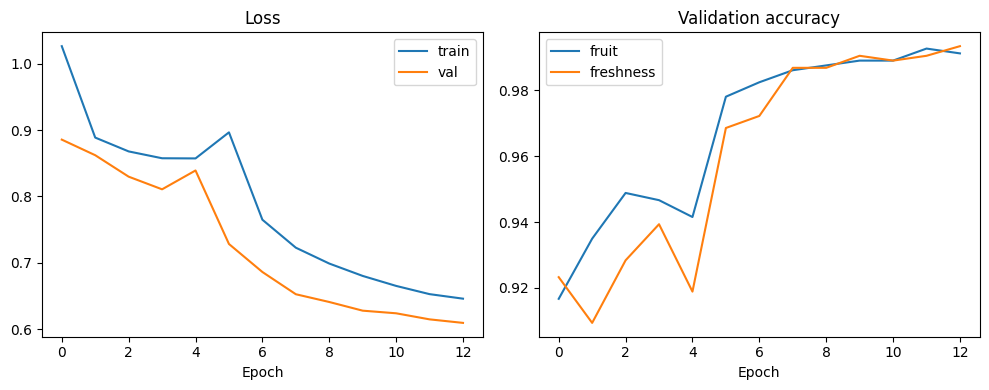

In [10]:
#Learning curves
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["val_fruit_acc"], label="fruit"); plt.plot(history["val_fresh_acc"], label="freshness")
plt.title("Validation accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.show()

=============== Test set (dataset) ===============
Fruit accuracy: 0.9928
              precision    recall  f1-score   support

       apple       0.99      0.99      0.99       292
      banana       0.99      1.00      1.00       294
       mango       1.00      0.99      1.00       585
      orange       0.99      0.98      0.99       209

    accuracy                           0.99      1380
   macro avg       0.99      0.99      0.99      1380
weighted avg       0.99      0.99      0.99      1380

Freshness accuracy: 0.9964
Freshness F1 (macro): 0.9964

Per-fruit freshness performance:
  apple      accuracy 1.000 | images 292
  banana     accuracy 1.000 | images 294
  mango      accuracy 0.991 | images 585
  orange     accuracy 1.000 | images 209


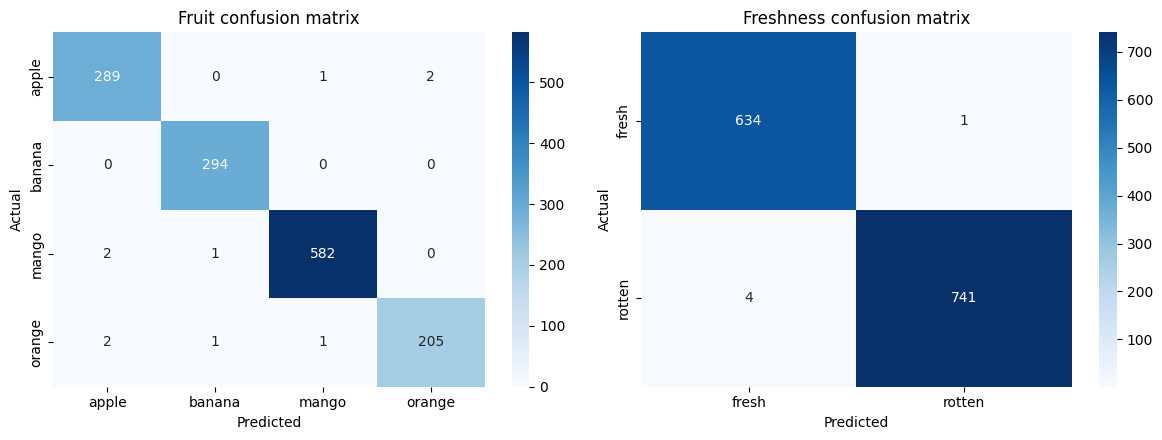


Latency: 5.77 ms per image | FPS: 173.4


In [11]:
#evaluations metrices
def evaluate(loader, title="Test set"):
    model.eval()
    fr_true, fr_pred, fs_true, fs_pred = [], [], [], []
    with torch.no_grad():
        for images, fruit, fresh in loader:
            out_fruit, out_fresh = model(images.to(device))
            fr_pred += out_fruit.argmax(1).cpu().tolist()
            fs_pred += out_fresh.argmax(1).cpu().tolist()
            fr_true += fruit.tolist(); fs_true += fresh.tolist()

    print(f"=============== {title} ===============")
    print("Fruit accuracy:", round(accuracy_score(fr_true, fr_pred), 4))
    print(classification_report(fr_true, fr_pred, labels=range(len(fruit_list)),
                                target_names=fruit_list, zero_division=0))
    print("Freshness accuracy:", round(accuracy_score(fs_true, fs_pred), 4))
    print("Freshness F1 (macro):", round(f1_score(fs_true, fs_pred, average="macro"), 4))

    print("\nPer-fruit freshness performance:")
    for i, f in enumerate(fruit_list):
        idx = [k for k, t in enumerate(fr_true) if t == i]
        if idx:
            t = [fs_true[k] for k in idx]; p = [fs_pred[k] for k in idx]
            print(f"  {f:10s} accuracy {accuracy_score(t, p):.3f} | images {len(idx)}")

    plt.figure(figsize=(12, 4.5))
    plt.subplot(1, 2, 1)
    sns.heatmap(confusion_matrix(fr_true, fr_pred, labels=range(len(fruit_list))), annot=True,
                fmt="d", cmap="Blues", xticklabels=fruit_list, yticklabels=fruit_list)
    plt.title("Fruit confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.subplot(1, 2, 2)
    sns.heatmap(confusion_matrix(fs_true, fs_pred, labels=[0, 1]), annot=True, fmt="d",
                cmap="Blues", xticklabels=fresh_list, yticklabels=fresh_list)
    plt.title("Freshness confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()

evaluate(test_loader, "Test set (dataset)")

dummy = torch.randn(1, 3, 224, 224).to(device)
with torch.no_grad():
    for _ in range(10): model(dummy)
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()
    for _ in range(100): model(dummy)
    if device.type == "cuda": torch.cuda.synchronize()
    total = time.time() - start
print(f"\nLatency: {total / 100 * 1000:.2f} ms per image | FPS: {100 / total:.1f}")

In [12]:
for d in sorted(Path("/content/drive/MyDrive/fresh_vs_rotten_fruit").iterdir()):
    print(d.name, "(folder)" if d.is_dir() else "")

fresh_vs_rotten_dataset.zip 
fresh_vs_rotten_fruit_new.ipynb 
fresh_vs_rotten_fruit_old.ipynb 
fresh_vs_rotten_my_dataset (folder)
fresh_vs_rotten_my_test_dataset (folder)


fresh_apple     photos: 5
fresh_banana    photos: 5
fresh_mango     photos: 5
fresh_orange    photos: 5
rotten_apple    photos: 5
rotten_banana   photos: 5
rotten_mango    photos: 5
rotten_orange   photos: 5
=============== Special test folder (never trained on) ===============
Fruit accuracy: 0.975
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        10
      banana       1.00      1.00      1.00        10
       mango       1.00      0.90      0.95        10
      orange       0.91      1.00      0.95        10

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40

Freshness accuracy: 0.975
Freshness F1 (macro): 0.975

Per-fruit freshness performance:
  apple      accuracy 1.000 | images 10
  banana     accuracy 0.900 | images 10
  mango      accuracy 1.000 | images 10
  orange     accuracy 1.000 | images 10


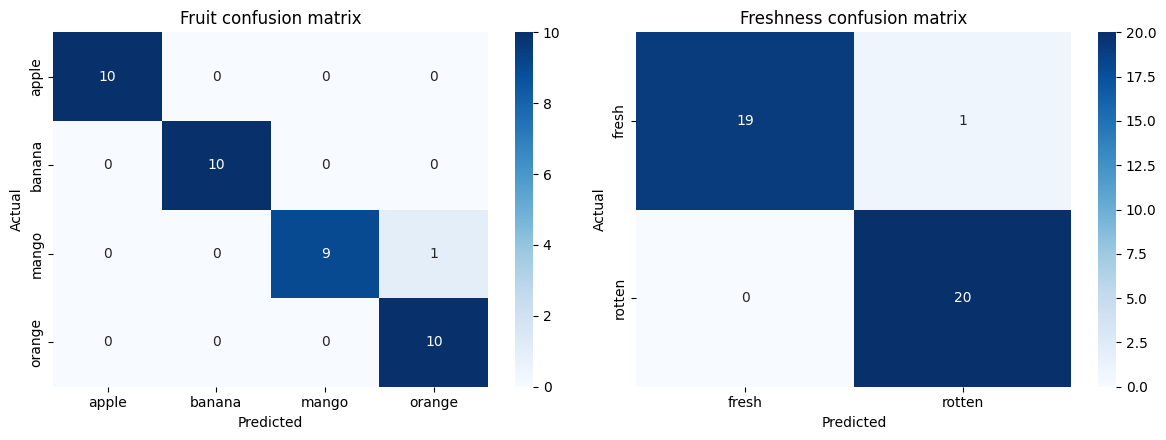

In [13]:
#testing with a manual test set.
SPECIAL_TEST = Path("/content/drive/MyDrive/fresh_vs_rotten_fruit/fresh_vs_rotten_my_test_dataset")

# Copy only the non-empty class folders to a temporary place
TMP = Path("/content/special_test")
if TMP.exists():
    shutil.rmtree(TMP)
for cls_dir in sorted(SPECIAL_TEST.iterdir()):
    if not cls_dir.is_dir():
        continue
    files = [f for f in cls_dir.glob("*") if f.suffix.lower() in exts]
    print(f"{cls_dir.name:15s} photos: {len(files)}")
    if files:
        (TMP / cls_dir.name).mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy(f, TMP / cls_dir.name / f.name)

special_data = FruitData(TMP, eval_tf)
evaluate(DataLoader(special_data, batch_size=32), "Special test folder (never trained on)")

In [14]:
#saving the model with the manual test set.
torch.save(model.state_dict(), "/content/fruit_model.pth")
with open("/content/labels.json", "w") as f:
    json.dump({"fruits": fruit_list, "fresh": fresh_list}, f)

!cp /content/fruit_model.pth /content/labels.json /content/drive/MyDrive/
print("Model saved!")

Model saved!


In [15]:
#copying the files again
!cp /content/drive/MyDrive/fruit_model.pth /content/drive/MyDrive/labels.json /content/
!ls -lh /content/fruit_model.pth /content/labels.json

-rw-r--r-- 1 root root 8.8M Nov 14 18:48 /content/fruit_model.pth
-rw-r--r-- 1 root root   80 Nov 14 18:48 /content/labels.json


In [16]:
%%writefile /content/app.py
#code to put whole into streamlit, to give it a real application like look.
import json, time
import streamlit as st
import torch, torch.nn as nn
from torchvision import models, transforms
from PIL import Image, ImageOps, ImageDraw, ImageFont

try:
    import av
    from streamlit_webrtc import webrtc_streamer, VideoProcessorBase, RTCConfiguration
    WEBRTC_OK = True
except ImportError:
    WEBRTC_OK = False

st.set_page_config(page_title="Fresh vs Rotten", layout="centered")

st.markdown("""
<style>
    ::selection { text-align: center; background: #10b981; color: #030A30; }

    .stApp {
        background-color: #090B1F;
    }
    /* Center everything inside the main app container */
    .block-container {
        padding-top: 3rem;
        max-width: 700px;
        background: linear-gradient( #1F090B 100%);
        border-radius: 16px;
        box-shadow: 0 10px 25px rgba(0, 0, 0, 0.05);
        text-align: center;
        display: flex;
        flex-direction: column;
        align-items: center;
    }

    .block-container > div {
        width: 100%;
    }

    /* Vibrant Title */
    .title {
        font-size: 2.2rem;
        font-weight: 800;
        background: linear-gradient(90deg, #C2DFED, #A5AFE4);
        -webkit-background-clip: text;
        -webkit-text-fill-color: transparent;
        text-align: center;
        margin-bottom: 0.2rem;
    }

    /* Clean Subtitle */
    .subtitle {
        color: #EBEEF9;
        font-size: 1.1rem;
        text-align: center;
        margin-bottom: 2rem;
        font-weight: 500;
    }

    /* Centered Result Cards */
    .card {
        padding: 1.5rem;
        border-radius: 16px;
        margin: 1.2rem auto;
        border-left: 8px solid;
        box-shadow: 0 4px 12px rgba(0,0,0,0.05);
        width: 90%;
        text-align: center;
    }

    /* Fresh State */
    .fresh {
        background: #ecfdf5;
        border-color: #10b981;
        color: #065f46;
    }

    /* Rotten State */
    .rotten {
        background: #fef2f2;
        border-color: #ef4444;
        color: #991b1b;
    }

    .row { font-size: 1.3rem; margin: 0.4rem 0; text-align: center; }
    .label { font-weight: 500; opacity: 0.85; }
    .value { font-weight: 700; }

    /* Center file uploader & images */
    .stFileUploader {
        max-width: 400px;
        margin: 0 auto;
    }

    div.stImage img {
        display: block;
        margin-left: auto;
        margin-right: auto;
        border-radius: 12px;
    }
</style>
""", unsafe_allow_html=True)
st.markdown('<div class="title">Fresh vs Rotten Fruit</div>', unsafe_allow_html=True)
st.markdown('<div class="subtitle">Check the freshness of your fruits</div>', unsafe_allow_html=True)
st.markdown('<div class="subtitle">Apple | Banana | Orange | Mango</div>', unsafe_allow_html=True)


class FruitNet(nn.Module):
    def __init__(self, n_fruit, n_fresh, pretrained=True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        self.features = models.mobilenet_v2(weights=weights).features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.3)
        self.fruit_head = nn.Linear(1280, n_fruit)
        self.fresh_head = nn.Linear(1280, n_fresh)
    def forward(self, x):
        x = self.drop(self.pool(self.features(x)).flatten(1))
        return self.fruit_head(x), self.fresh_head(x)

@st.cache_resource
def load_model():
    labels = json.load(open("/content/labels.json"))
    model = FruitNet(len(labels["fruits"]), len(labels["fresh"]), pretrained=False)
    model.load_state_dict(torch.load("/content/fruit_model.pth", map_location="cpu"))
    model.eval()
    return model, labels["fruits"], labels["fresh"]

model, fruits, fresh_names = load_model()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(image):
    image = ImageOps.fit(image, (224, 224))
    x = transform(image).unsqueeze(0)
    start = time.time()
    with torch.no_grad():
        out_fruit, out_fresh = model(x)
        p_fruit = torch.softmax(out_fruit, 1)[0]
        p_fresh = torch.softmax(out_fresh, 1)[0]
    ms = (time.time() - start) * 1000
    fc, fi = p_fruit.max(0)
    sc, si = p_fresh.max(0)
    return fruits[fi.item()], fc.item(), fresh_names[si.item()], sc.item(), ms

def show_result(image):
    fruit, fc, status, sc, ms = predict(image)
    st.markdown(f"""
    <div class="card {status}">
        <div class="row"><span class="label">Fruit : </span><span class="value">{fruit.title()}</span></div>
        <div class="row"><span class="label">Status : </span><span class="value">{status.title()}</span></div>
    </div>
    """, unsafe_allow_html=True)
    st.markdown(f"**Fruit confidence:** {fc * 100:.1f}%")
    st.progress(fc)
    st.markdown(f"**Status confidence:** {sc * 100:.1f}%")
    st.progress(sc)
    if min(fc, sc) < 0.60:
        st.warning("Low confidence. Place one fruit in the centre with good lighting and retry.")
    st.image(image, caption="Input image", width=350)
    st.caption(f"Inference time: {ms:.1f} ms")

def load_image(file):
    return ImageOps.exif_transpose(Image.open(file)).convert("RGB")

if WEBRTC_OK:
    class FruitProcessor(VideoProcessorBase):
        def __init__(self):
            self.count = 0
            self.fruit, self.status, self.fc, self.sc = "", "", 0.0, 0.0

        def recv(self, frame):
            img = frame.to_image().convert("RGB")
            self.count += 1
            if self.count % 3 == 1:
                self.fruit, self.fc, self.status, self.sc, _ = predict(img)
            colour = (16, 185, 129) if self.status == "fresh" else (239, 68, 68)
            text = f"{self.fruit.title()} {self.fc*100:.0f}% | {self.status.title()} {self.sc*100:.0f}%"
            if min(self.fc, self.sc) < 0.60:
                colour, text = (120, 120, 120), "Not sure"
            draw = ImageDraw.Draw(img)
            w, h = img.size
            try:
                font = ImageFont.load_default(size=max(18, w // 24))
            except TypeError:
                font = ImageFont.load_default()
            draw.rectangle([0, 0, w - 1, h - 1], outline=colour, width=6)
            draw.rectangle([0, 0, w, max(40, w // 12)], fill=colour)
            draw.text((12, 6), text, fill=(255, 255, 255), font=font)
            return av.VideoFrame.from_image(img)

tab1, tab2 = st.tabs(["Upload", "Camera"])

with tab1:
    file = st.file_uploader("Upload a fruit photo", type=["jpg", "jpeg", "png"])
    if file is not None:
        show_result(load_image(file))

with tab2:
    photo = st.camera_input("Take a photo of the fruit")
    if photo is not None:
        show_result(load_image(photo))

Writing /content/app.py


In [17]:
!pkill -f "[s]treamlit"
!pkill -f "[c]loudflared"

#generating streamlit link
import subprocess, time, re, os

!pip install -q streamlit streamlit-webrtc
if not os.path.exists("cloudflared"):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
    !chmod +x cloudflared

time.sleep(2)
subprocess.Popen(["streamlit", "run", "/content/app.py",
                  "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)

proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                        stderr=subprocess.PIPE, text=True)
for line in proc.stderr:
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
    if m:
        print("Open your app here:", m.group(0))
        break

Open your app here: https://middle-viewers-containing-illustration.trycloudflare.com
